In [1]:
import pandas as pd
import numpy as np
from collections import Counter
from sklearn.model_selection import train_test_split
import numpy as np
from sklearn.linear_model import LinearRegression ,Ridge, Lasso, ElasticNet
import matplotlib.pyplot as plt
from sklearn.metrics import r2_score, mean_absolute_error, root_mean_squared_error
from sklearn.preprocessing import MinMaxScaler, StandardScaler
from sklearn.preprocessing import PolynomialFeatures

# ML2_Supervised learning

## 1.1 Аналитический вывод формулы оптимальных весов

**Постановка.** Пусть $X \in \mathbb{R}^{n \times d}$ — матрица объект-признак (строки — объекты, столбцы — признаки; первый столбец состоит из единиц, что позволяет включить свободный член $b$ в вектор весов), $y \in \mathbb{R}^{n}$ — вектор целевой переменной, $w \in \mathbb{R}^{d}$ — вектор параметров модели. Предсказание модели:

$$\hat{y} = Xw$$

**Функционал ошибки.** Минимизируем сумму квадратов остатков:

$$L(w) = \|y - Xw\|_2^2 = (y - Xw)^T (y - Xw) \longrightarrow \min_{w}$$

Множитель $\tfrac{1}{n}$ (переход к MSE) не влияет на положение минимума, поэтому опускается.

**Раскрытие скобок.** Используя $(A - B)^T = A^T - B^T$ и $(Xw)^T = w^T X^T$:

$$L(w) = (y^T - w^T X^T)(y - Xw) = y^T y - y^T X w - w^T X^T y + w^T X^T X w$$

Слагаемые $y^T X w$ и $w^T X^T y$ — скаляры размера $1 \times 1$, причём $(y^T X w)^T = w^T X^T y$. Транспонирование скаляра не меняет его значения, следовательно эти слагаемые равны и объединяются:

$$L(w) = y^T y - 2\, y^T X w + w^T X^T X w$$

**Дифференцирование.** Применяем правила матричного дифференцирования $\nabla_w (a^T w) = a$ и $\nabla_w (w^T A w) = 2Aw$ при $A^T = A$. Матрица $A = X^T X$ симметрична, так как $(X^T X)^T = X^T (X^T)^T = X^T X$. Первое слагаемое от $w$ не зависит и обращается в нуль:

$$\nabla_w L(w) = -2 X^T y + 2 X^T X w$$

**Условие экстремума.** Функционал $L(w)$ — выпуклая квадратичная форма (матрица Гессе $\nabla^2_w L = 2 X^T X$ неотрицательно определена), поэтому стационарная точка является точкой глобального минимума:

$$\nabla_w L(w) = 0 \quad \Longrightarrow \quad -2 X^T y + 2 X^T X w = 0$$

$$X^T X w = X^T y$$

Полученное соотношение называется **нормальным уравнением**. Домножая обе части слева на $(X^T X)^{-1}$ (при условии невырожденности матрицы $X^T X$):

$$\boxed{\ \hat{w} = \left( X^T X \right)^{-1} X^T y\ }$$

## 1.2. Изменение решения при добавлении L1- и L2-регуляризации

Регуляризация вводится как аддитивный штраф за сложность модели в функционале качества:

$$\min_{w} \sum_{i=1}^{N} L\left(f(x_i, w), y_i\right) + \alpha R(w)$$

Здесь $R(w)$ — регуляризатор, $\alpha \ge 0$ — гиперпараметр, задающий баланс между точностью на обучающей выборке и сложностью модели. Смысл добавки: решения с большими по модулю весами становятся «дорогими», что ограничивает способность модели подстраиваться под шум.

### L2-регуляризация (Ridge)

$$L(w) = \|y - Xw\|_2^2 + \alpha \|w\|_2^2 = (y - Xw)^T(y - Xw) + \alpha\, w^T w$$

Регуляризатор — гладкая квадратичная функция, поэтому вывод полностью повторяет случай OLS. Применяя $\nabla_w (w^T w) = 2w$:

$$\nabla_w L(w) = -2X^T y + 2X^T X w + 2\alpha w = 0$$

$$X^T X w + \alpha w = X^T y$$

Представив $\alpha w = \alpha I w$, выносим $w$ за скобку:

$$\left( X^T X + \alpha I \right) w = X^T y$$

$$\boxed{\ \hat{w}_{\text{ridge}} = \left( X^T X + \alpha I \right)^{-1} X^T y\ }$$

**Что изменилось.** Аналитическое решение сохраняется, но к матрице $X^T X$ прибавляется $\alpha I$. Это сдвигает весь спектр собственных значений вправо на величину $\alpha$: если при мультиколлинеарности некоторые $\lambda_i \approx 0$ и матрица близка к вырожденной, то после добавки $\lambda_i + \alpha > 0$. Матрица становится положительно определённой и, следовательно, обратимой при любом $\alpha > 0$, а число обусловленности уменьшается. Таким образом, решение существует и единственно даже при $d > n$ и при линейно зависимых признаках.

В градиентном спуске изменение сводится к дополнительному слагаемому в шаге:

$$w^{k+1} = w^k - \gamma\left( -2X^T(y - Xw^k) + 2\alpha w^k \right)$$

что эквивалентно домножению весов на коэффициент $(1 - 2\gamma\alpha) < 1$ на каждой итерации. Отсюда второе название метода — **weight decay** (затухание весов).

### L1-регуляризация (Lasso)

$$L(w) = \|y - Xw\|_2^2 + \alpha \|w\|_1 = \|y - Xw\|_2^2 + \alpha \sum_{j=1}^{d} |w_j|$$

Принципиальное отличие: функция $|w_j|$ **недифференцируема** в точке $w_j = 0$. Производная равна

$$\frac{\partial |w_j|}{\partial w_j} = \operatorname{sign}(w_j) = \begin{cases} +1, & w_j > 0 \\ -1, & w_j < 0 \\ \text{не определена}, & w_j = 0 \end{cases}$$

Следовательно, условие $\nabla L = 0$ неприменимо во всём пространстве, и **замкнутого аналитического решения не существует**. Задача остаётся выпуклой, но решается только численно. Используются:

* субградиентный спуск — вместо производной в точке излома берётся любой элемент субдифференциала $\partial |w_j|\big|_{w_j = 0} = [-1, 1]$;
* координатный спуск — метод, реализованный в `sklearn.linear_model.Lasso`; оптимизация ведётся по одной координате за раз, что даёт для каждого веса решение в явном виде через оператор мягкой пороговой обработки (soft-thresholding):

$$w_j = \operatorname{sign}(z_j)\cdot \max\left(|z_j| - \alpha,\ 0\right)$$

Именно оператор $\max(\cdot, 0)$ обнуляет вес точно, если его «сырое» значение $z_j$ по модулю не превышает порога $\alpha$.

**Что изменилось.** Аналитическое решение исчезает; требуется итеративный численный метод. Кроме того, меняется характер решения: оно становится **разреженным** — часть весов обращается в строгий ноль (см. п. 1.3).

### ElasticNet

Комбинация обоих штрафов с параметром $\rho \in [0, 1]$ (в `sklearn` — `l1_ratio`):

$$L(w) = \|y - Xw\|_2^2 + \alpha \rho \|w\|_1 + \frac{\alpha (1 - \rho)}{2} \|w\|_2^2$$

При $\rho = 1$  Lasso, при $\rho = 0$  Ridge. Наличие L1-компоненты сохраняет недифференцируемость, поэтому аналитического решения также нет — используется координатный спуск. Модель наследует оба свойства: отбор признаков от L1 и устойчивость к мультиколлинеарности от L2. Практическое преимущество перед чистым Lasso: при группе сильно скоррелированных признаков Lasso произвольно оставляет один из них и зануляет остальные, тогда как ElasticNet распределяет веса по всей группе.

### Сводка

| Модель | Регуляризатор | Аналитическое решение | Метод оптимизации | Свойство решения |
|---|---|---|---|---|
| OLS | — | $(X^TX)^{-1}X^Ty$ | Прямое / GD | Неустойчиво при $\operatorname{rank}(X) < d$ |
| Ridge | $\alpha\|w\|_2^2$ | $(X^TX + \alpha I)^{-1}X^Ty$ | Прямое / GD | Веса сжимаются, нулей нет |
| Lasso | $\alpha\|w\|_1$ | Не существует | Координатный / субградиентный спуск | Разреженное, часть весов $= 0$ |
| ElasticNet | $\alpha(\rho\|w\|_1 + \frac{1-\rho}{2}\|w\|_2^2)$ | Не существует | Координатный спуск | Разреженное + групповой эффект |

**Важное замечание о нормализации.** Штраф $R(w)$ одинаков для всех компонент вектора весов, тогда как сами веса зависят от масштаба соответствующих признаков. Признак с большим диапазоном значений получает малый по модулю вес и, соответственно, малый штраф, и наоборот. Поэтому регуляризованные модели требуют обязательного предварительного масштабирования признаков — иначе регуляризация штрафует признаки за единицы измерения, а не за реальную бесполезность. Свободный член $b$ при этом из регуляризации исключается, так как он не связан с конкретным признаком и его штрафование сделало бы модель зависимой от сдвига целевой переменной.

## 1.3. Почему L1-регуляризация используется для отбора признаков

L1 даёт **разреженное** решение: часть весов обращается в строгий ноль. Признаки с нулевыми весами не участвуют в предсказании — это эквивалентно их исключению из модели. Отсюда применение Lasso как встроенного (embedded) метода отбора признаков.

### Причина: разный характер штрафа

Сравним производные регуляризаторов по отдельному весу:

$$\frac{\partial}{\partial w_j}\left(\alpha \|w\|_2^2\right) = 2\alpha w_j \qquad \frac{\partial}{\partial w_j}\left(\alpha \|w\|_1\right) = \alpha \operatorname{sign}(w_j)$$

У L2 сила, толкающая вес к нулю, **пропорциональна самому весу** и затухает при $w_j \to 0$: большие веса сжимаются сильно, малые почти не затрагиваются, нуля никто не достигает. У L1 сила **постоянна и равна $\alpha$**: малый вес получает такой же толчок, как и большой. Если вклад признака в уменьшение основной части функционала меньше $\alpha$, вес доходит до нуля и остаётся там.

Это видно из решения координатным спуском (метод, используемый в `sklearn.linear_model.Lasso`), где для каждой координаты применяется оператор мягкой пороговой обработки:

$$w_j = \operatorname{sign}(z_j) \cdot \max\left(|z_j| - \alpha,\ 0\right)$$

где $z_j$ — оптимальное значение веса без регуляризации. При $|z_j| \le \alpha$ оператор $\max(\cdot,\, 0)$ даёт **точный ноль**; порог $\alpha$ определяет, какие признаки отбрасываются.

### Геометрическая интерпретация

Задача эквивалентна условной оптимизации $\min_w \|y - Xw\|_2^2$ при ограничении $\|w\| \le t$. Линии уровня квадратичного функционала — эллипсоиды с центром в OLS-решении; решением является точка **первого касания** расширяющегося эллипсоида и допустимой области.

* **L1**: область $\|w\|_1 \le t$ — кросс-политоп (в 2D — ромб) с вершинами **на координатных осях**, где часть координат строго равна нулю. Вершина — негладкая точка, она «перехватывает» касание для целого конуса направлений, поэтому попадание в неё типично. С ростом размерности эффект усиливается: у $d$-мерного кросс-политопа $2d$ вершин, плюс рёбра и грани, где часть координат также нулевая.
* **L2**: область — шар с гладкой границей. Касание точно на координатной оси возможно лишь при специальной ориентации эллипсоида и составляет множество меры нуль. Веса сжимаются, но остаются ненулевыми.

Негладкость модуля в нуле и наличие вершины у допустимой области — одно и то же свойство с двух сторон. Оно же объясняет, почему у Lasso нет аналитического решения и почему субградиентный (в том числе стохастический градиентный) спуск обычно не даёт точных нулей: метод подходит к точке излома, но колеблется в её окрестности.

### Практический аспект

Степень разреженности регулируется параметром $\alpha$: при $\alpha \to 0$ решение стремится к МНК и нулей нет, с ростом $\alpha$ число нулевых весов монотонно растёт. Ограничение метода: при группе сильно скоррелированных признаков Lasso произвольно оставляет один из них и зануляет остальные, что делает отбор нестабильным — в таких случаях предпочтительнее ElasticNet.


![Геометрия L1 и L2 регуляризации](L2_L1_Elastic.png)

## 1.4. Как использовать линейные модели для нелинейных зависимостей

Модель называется линейной по признаку линейности **относительно параметров**, а не относительно исходных переменных:

$$f(x, w) = \sum_{j=1}^{d} w_j x_j + b$$

Это означает, что произвольное нелинейное преобразование самих признаков не выводит модель из класса линейных. Заменим исходные признаки на набор базисных функций $\varphi_1(x), \dots, \varphi_m(x)$:

$$f(x, w) = \sum_{j=1}^{m} w_j \varphi_j(x) + b$$

Модель остаётся линейной по $w$, поэтому весь аппарат сохраняется без изменений: функционал по-прежнему является выпуклой квадратичной формой, справедливо нормальное уравнение $\hat{w} = (\Phi^T \Phi)^{-1}\Phi^T y$ (где $\Phi$ — матрица преобразованных признаков), применимы градиентный спуск и обе регуляризации. При этом зависимость $f$ от исходной переменной $x$ становится нелинейной.

### Основные способы преобразования

**Полиномиальные признаки.** Наиболее распространённый подход: к исходным признакам добавляются их степени и попарные произведения. Для двух признаков степени 2:

$$\varphi(x_1, x_2) = \left(1,\ x_1,\ x_2,\ x_1^2,\ x_1 x_2,\ x_2^2\right)$$

Произведения $x_1 x_2$ дополнительно позволяют учесть **взаимодействие** признаков. В `sklearn` реализовано в `PolynomialFeatures(degree=n)`.

**Функциональные преобразования отдельных признаков:** $\log(x)$, $\exp(x)$, $\sqrt{x}$, $1/x$. Применяются, когда характер зависимости известен из предметной области; логарифмирование также используется для признаков с тяжёлым правым хвостом распределения.

**Периодические базисы:** $\sin(\omega x)$, $\cos(\omega x)$ — для данных с сезонностью или циклической структурой (время суток, день недели, месяц).

**Преобразование целевой переменной.** Отдельный приём: при скошенном распределении $y$ модель обучается на $\log(1 + y)$, а прогноз возвращается обратным преобразованием $\exp(\hat{y}) - 1$. Формально это меняет не модель, а вид зависимости — линейная связь в логарифмической шкале соответствует мультипликативной в исходной.

### Ограничения подхода

Число полиномиальных признаков растёт как $\binom{d + n}{n}$, то есть комбинаторно быстро по степени $n$ и размерности $d$. Отсюда три следствия:

1. **Переобучение.** Богатый базис позволяет модели подстраиваться под шум; ошибка на обучении падает, на тесте — растёт.
2. **Мультиколлинеарность.** Степени одного признака сильно скоррелированы между собой, матрица $\Phi^T\Phi$ становится плохо обусловленной, веса — большими и неустойчивыми.
3. **Различие масштабов.** Признаки вида $x^{10}$ на несколько порядков превосходят $x$ по величине, что нарушает работу градиентного спуска и делает штраф регуляризации несопоставимым между признаками.

Поэтому полиномиальные признаки на практике применяются в сочетании с **масштабированием** и **регуляризацией**. 

## 2 Preprocessing data

In [2]:
df = pd.read_json('data/train.json')
train_df, test_df = train_test_split(df, test_size=0.25, random_state=21)


In [3]:
first = train_df['price'].quantile(0.01)
nn = train_df['price'].quantile(0.99)
train_df = train_df[train_df['price'].between(first,nn, inclusive= 'neither')].copy()
test_df = test_df[test_df['price'].between(first,nn, inclusive= 'neither')].copy()

In [4]:
train_df['features'].iloc[0]

['Doorman',
 'Fitness Center',
 'Elevator',
 'PublicOutdoor',
 'Laundry in Unit',
 'Dishwasher',
 'Cats Allowed',
 'Dogs Allowed',
 'Garage',
 'Laundry in Building']

In [5]:
all_featers = []
for index, row in train_df.iterrows():
    for feature in row['features']:
        all_featers.append(feature.replace(' ',''))
cnt = Counter(all_featers)  


In [6]:
len(set(all_featers))

1263

In [7]:
cnt.most_common(20)

[('Elevator', 18935),
 ('HardwoodFloors', 17352),
 ('CatsAllowed', 17351),
 ('DogsAllowed', 16253),
 ('Doorman', 15302),
 ('Dishwasher', 15043),
 ('NoFee', 13355),
 ('LaundryinBuilding', 11978),
 ('FitnessCenter', 9741),
 ('Pre-War', 6729),
 ('LaundryinUnit', 6351),
 ('RoofDeck', 4787),
 ('OutdoorSpace', 3833),
 ('DiningRoom', 3631),
 ('HighSpeedInternet', 3134),
 ('Balcony', 2122),
 ('LaundryInBuilding', 1958),
 ('SwimmingPool', 1925),
 ('NewConstruction', 1844),
 ('Terrace', 1611)]

In [8]:
top20_names = []
for key, value in cnt.most_common(20):
    top20_names.append(key)
    
top20_names 

['Elevator',
 'HardwoodFloors',
 'CatsAllowed',
 'DogsAllowed',
 'Doorman',
 'Dishwasher',
 'NoFee',
 'LaundryinBuilding',
 'FitnessCenter',
 'Pre-War',
 'LaundryinUnit',
 'RoofDeck',
 'OutdoorSpace',
 'DiningRoom',
 'HighSpeedInternet',
 'Balcony',
 'LaundryInBuilding',
 'SwimmingPool',
 'NewConstruction',
 'Terrace']

**Функция для  добавления необходимых бинарных признаков**

In [9]:
def add_binary_features(df, top_names:list):
    df = df.copy()
    df['features_clean'] = df['features'].apply(lambda lst: {f.replace(' ','') for f in lst})
    for name in top_names:
        df[name] = df['features_clean'].apply(lambda s:  int(name in s))
    return df[top_names + ['bathrooms','bedrooms','price']] 


In [10]:
train_df = add_binary_features(train_df,top20_names)
feature_list = top20_names + ['bathrooms','bedrooms']
len(feature_list)

22

In [11]:
X_train, y_train = train_df[feature_list], train_df['price']

In [12]:
test_df = add_binary_features(test_df,top20_names)
X_test, y_test = test_df[feature_list], test_df['price']

In [13]:
print(y_train.describe())

count    36250.000000
mean      3531.378593
std       1590.504670
min       1489.000000
25%       2500.000000
50%       3150.000000
75%       4050.000000
max      12995.000000
Name: price, dtype: float64


In [14]:
class MyLinearRegressionAnalytic:

    def __init__(self):
        self.w = None

    def _prepare(self, X):
        X = np.asarray(X, dtype= np.float64)
        ones = np.ones((X.shape[0],1))
        return np.hstack([ones,X])

    def fit(self,X, y):
        X = self._prepare(X)
        y = np.asarray(y, dtype= np.float64)
        self.w = np.linalg.solve(X.T @ X, X.T @ y)
        return self

    def predict(self, X):
        return self._prepare(X) @ self.w

    @property
    def coef_(self):
        return self.w[1:]

    @property
    def intercept_(self):
        return self.w[0]


In [15]:
my =MyLinearRegressionAnalytic().fit(X_train,y_train)
sk = LinearRegression().fit(X_train,y_train)


In [16]:
print(np.abs(my.coef_ - sk.coef_).max())
print(my.intercept_ - sk.intercept_)

7.418066161335446e-12
-1.3642420526593924e-12


**Градиаентный спуск**

$$\nabla_w L(w) = -2 X^T \left( y - X w \right)$$

Шаг обновления:

$$w^{k+1} = w^{k} - \gamma \, \nabla_w L\!\left(w^{k}\right)$$

In [17]:
class MyGDLinearRegression(MyLinearRegressionAnalytic):
    def __init__(self, lr = 0.1, n_iter = 1000):
        self.lr = lr
        self.n_iter = n_iter
        self.w = None

    def fit(self, X, y):
        X = self._prepare(X)
        y = np.asarray(y, dtype=np.float64)
        n, d = X.shape
        self.w = np.zeros(d)
        self.loss_history = []

        for i in range(self.n_iter):
            y_pred = X @ self.w
            eps = y - y_pred
            grad = - (2 / n) * (X.T @ eps)
            self.w = self.w - self.lr * grad
            loss = np.mean(eps ** 2) # MSE
            self.loss_history.append(loss)
        return self
        


In [18]:
gd = MyGDLinearRegression().fit(X_train, y_train)

In [19]:
print(gd.loss_history[-1])
print(np.mean((y_train - my.predict(X_train))**2))

1049368.7801121864
1049367.8916331504


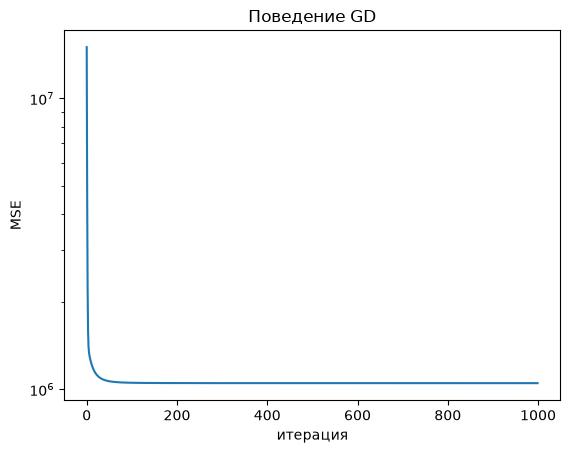

In [20]:
plt.plot(gd.loss_history)
plt.xlabel('итерация') 
plt.ylabel('MSE')
plt.yscale('log')
plt.title('Поведение GD')
plt.show()

In [21]:
class MySGDLinearRegression(MyLinearRegressionAnalytic):
    def __init__(self, lr = 1e-4, n_epochs = 10, random_state = 21, decay = 0.0):
        self.lr = lr
        self.n_epochs = n_epochs
        self.w = None
        self.random_state = random_state
        self.decay = decay

    def fit(self, X, y):
        X = self._prepare(X)
        y = np.asarray(y, dtype = np.float64)
        n, d = X.shape
        self.w = np.zeros(d)
        self.loss_history = []

        rng = np.random.default_rng(self.random_state) # как раз для детерменнированности мы фиксируем наше разбиение при помощи генератора, чтобы оно было воспроизводимым  

        for epoch in range(self.n_epochs):
            lr_epoch = self.lr / np.sqrt(1 + epoch)
            indices = rng.permutation(n) # берём и перемешиваем наши данные в псевдослучайном разбиении, которое мы заффиксировали генератором
            for i in indices:
                y_pred = X[i] @ self.w
                eps = y[i] - y_pred
                grad = -2 * X[i] * eps
                self.w = self.w - lr_epoch * grad
            loss = np.mean((y - X @ self.w) ** 2)
            self.loss_history.append(loss)
        return self

                


In [22]:
sgd = MySGDLinearRegression().fit(X_train, y_train)
print(sgd.loss_history)
print('аналитика:', np.mean((y_train - my.predict(X_train)) ** 2))

[np.float64(1083769.699184484), np.float64(1059574.1094770627), np.float64(1055049.8854066948), np.float64(1052749.1417454288), np.float64(1051747.2585381244), np.float64(1051221.7898453912), np.float64(1050827.1418691971), np.float64(1052244.6405305066), np.float64(1050463.5116550375), np.float64(1051775.7065095834)]
аналитика: 1049367.8916331504


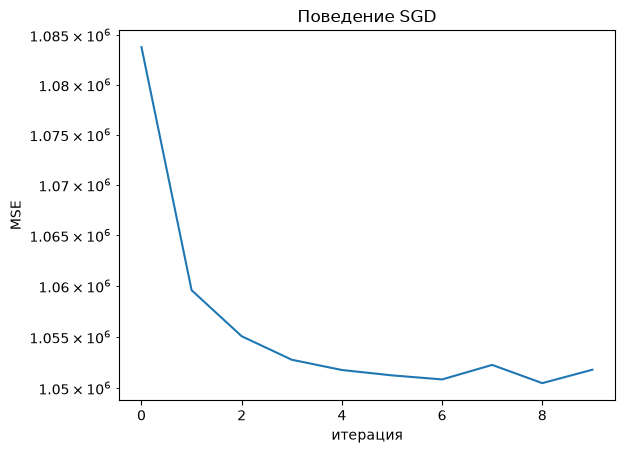

In [23]:
plt.plot(sgd.loss_history)
plt.xlabel('итерация') 
plt.ylabel('MSE')
plt.yscale('log')
plt.title('Поведение SGD')
plt.show()

Формула коэффициента детерминации:

$$R^2 = 1 - \frac{SS_{res}}{SS_{tot}} = 1 - \frac{\sum_{i=1}^{n}(y_i - \hat{y}_i)^2}{\sum_{i=1}^{n}(y_i - \bar{y})^2}$$

где $\hat{y}_i$ — предсказание модели, а $\bar{y}$ — среднее истинных значений той выборки, на которой считается метрика.

Можно переписать через MSE: поделив числитель и знаменатель на $n$, получим

$$R^2 = 1 - \frac{MSE_{model}}{\operatorname{Var}(y)}$$


In [24]:
def my_r2_score(y, y_predict):
    r2 = 1 - np.sum((y - y_predict )** 2) / (np.sum((y - np.mean(y)) **2))
    return r2

In [25]:
def my_mae(y , y_predict):
    n = len(y)
    mae =  np.sum(np.abs(y - y_predict))/ n
    return mae

In [26]:
def my_rmse(y , y_predict):
    n = len(y)
    rmse =  np.sqrt(np.sum((y - y_predict) ** 2)/ n)
    return rmse

In [27]:
print('difference r2_score:',my_r2_score(y_train, my.predict(X_train)) - r2_score(y_train, my.predict(X_train)))
print('difference mae:' ,my_mae(y_train, my.predict(X_train)) - mean_absolute_error(y_train, my.predict(X_train)))
print('difference rmse:' ,my_rmse(y_train, my.predict(X_train)) - root_mean_squared_error(y_train, my.predict(X_train)))


difference r2_score: 0.0
difference mae: 0.0
difference rmse: 0.0


Функция для заполнения таблицы

In [28]:
metric_funcs = {
    'MAE': my_mae,
    'RMSE': my_rmse,
    'R2' : my_r2_score 
}

results = {name_func : pd.DataFrame(columns=['train','test'], dtype=float) for name_func in metric_funcs}
def evaluate(model, name, X_train, y_train, X_test, y_test):
    y_train, y_test = np.asarray(y_train), np.asarray(y_test)
    pred_train, pred_test = np.asarray(model.predict(X_train)), np.asarray(model.predict(X_test))
    for metric, func in metric_funcs.items():
        results[metric].loc[name] = [func(y_train, pred_train), func(y_test, pred_test)]

def show_results():
    for metric, table in results.items():
        print(f'\nresult_{metric}')
        display(table.rename_axis('model').reset_index())

def remove_model(name):
    for metric in results:
        results[metric] = results[metric].drop(name,errors='ignore' )

In [29]:
evaluate(my, 'My LinearRegression Analytic ',X_train, y_train, X_test, y_test)
evaluate(gd, 'My GD default',X_train, y_train, X_test, y_test)
evaluate(sgd, 'My SGD default', X_train, y_train, X_test, y_test)
evaluate(sk, 'Linreg default (sklearn)', X_train, y_train, X_test, y_test)
show_results()


result_MAE


,model,train,test
0,My LinearRegression Analytic,707.529523,712.738504
1,My GD default,707.528571,712.729122
2,My SGD default,702.910304,707.847662
3,Linreg default (sklearn),707.529523,712.738504



result_RMSE


,model,train,test
0,My LinearRegression Analytic,1024.386593,1036.259660
1,My GD default,1024.387024,1036.257852
2,My SGD default,1025.561167,1036.789977
3,Linreg default (sklearn),1024.386593,1036.259660



result_R2


,model,train,test
0,My LinearRegression Analytic,0.585170,0.564824
1,My GD default,0.585170,0.564825
2,My SGD default,0.584218,0.564378
3,Linreg default (sklearn),0.585170,0.564824


## 5. Регуляризованные модели: Ridge, Lasso, ElasticNet

Реализации повторяют функционалы из `sklearn.linear_model`. Во всех трёх моделях свободный член $w_0$ не штрафуется.

**Ridge** (`alpha = 1.0`):

$$L(w) = \|y - Xw\|_2^2 + \alpha\|w\|_2^2$$

**Lasso** (`alpha = 1.0`):

$$L(w) = \frac{1}{2n}\|y - Xw\|_2^2 + \alpha\|w\|_1$$

**ElasticNet** (`alpha = 1.0`, `l1_ratio` $= \rho = 0.5$):

$$L(w) = \frac{1}{2n}\|y - Xw\|_2^2 + \alpha\rho\|w\|_1 + \frac{\alpha(1-\rho)}{2}\|w\|_2^2$$

**Ridge** решается аналитически (вывод в п. 1.2):

$$\hat{w} = \left(X^T X + \alpha I'\right)^{-1} X^T y$$

где $I'$ — единичная матрица с нулём в позиции $[0, 0]$, что исключает свободный член из штрафа.

**Lasso и ElasticNet** решаются только численно, так как $|w_j|$ недифференцируем в нуле. Используется субградиентный спуск. Градиент ElasticNet:

$$\nabla_w L = -\frac{1}{n} X^T (y - Xw) + \alpha\rho\,\operatorname{sign}(w') + \alpha(1-\rho)\,w'$$

где $w'$ — вектор весов с обнулённой компонентой $w_0$. Lasso — частный случай при $\rho = 1$.

Шаг обновления:

$$w^{k+1} = w^{k} - \gamma\,\nabla_w L\left(w^{k}\right)$$

In [30]:
class MyRidgeAnalytic(MyLinearRegressionAnalytic):
    def __init__(self, alpha=1.0):
        self.alpha = alpha
        self.w = None

    def fit(self, X, y):
        X = self._prepare(X)
        y = np.asarray(y, dtype=np.float64)
        I = np.eye(X.shape[1])
        I[0, 0] = 0          # не штрафуем intercept
        self.w = np.linalg.solve(X.T @ X + self.alpha * I, X.T @ y)
        return self

In [31]:
class MyElasticNetGD(MyLinearRegressionAnalytic):
    def __init__(self, alpha=1.0, l1_ratio=0.5, lr=0.1, n_iter=3000):
        self.alpha = alpha
        self.l1_ratio = l1_ratio
        self.lr = lr
        self.n_iter = n_iter
        self.w = None

    def _penalty_grad(self, w):
        w_pen = w.copy()
        w_pen[0] = 0         # intercept без штрафа
        l1 = self.alpha * self.l1_ratio * np.sign(w_pen)          # субградиент 
        l2 = self.alpha * (1 - self.l1_ratio) * w_pen
        return l1 + l2

    def fit(self, X, y):
        X = self._prepare(X)
        y = np.asarray(y, dtype=np.float64)
        n, d = X.shape
        self.w = np.zeros(d)
        self.w[0] = y.mean()   # старт intercept с среднего, чтобы быстрее сошлось

        for _ in range(self.n_iter):
            eps = y - X @ self.w
            grad = -(X.T @ eps) / n + self._penalty_grad(self.w)
            self.w = self.w - self.lr * grad
        return self


class MyLassoGD(MyElasticNetGD):
    def __init__(self, alpha=1.0, lr=0.1, n_iter=3000):
        super().__init__(alpha=alpha, l1_ratio=1.0, lr=lr, n_iter=n_iter)

In [32]:
my_lasso = MyLassoGD().fit(X_train, y_train)

In [33]:
my_elastic = MyElasticNetGD().fit(X_train,y_train)

In [34]:
my_Ridge = MyRidgeAnalytic().fit(X_train,y_train)

In [35]:
sk_l = Lasso().fit(X_train,y_train)
sk_R = Ridge().fit(X_train,y_train)
sk_el = ElasticNet().fit(X_train,y_train)

In [36]:
evaluate(sk_l,'Lasso default (sklearn) ',X_train, y_train, X_test, y_test)
evaluate(my_lasso, 'My Lasso default',X_train, y_train, X_test, y_test)
evaluate(sk_R, 'Ridge default (sklearn)', X_train, y_train, X_test, y_test)
evaluate(my_Ridge, 'My Ridge default', X_train, y_train, X_test, y_test)
evaluate(sk_el, 'ElasticNet default (sklearn)', X_train, y_train, X_test, y_test)
evaluate(my_elastic, 'My ElasticNet default ', X_train, y_train, X_test, y_test)
show_results()


result_MAE


,model,train,test
0,My LinearRegression Analytic,707.529523,712.738504
1,My GD default,707.528571,712.729122
2,My SGD default,702.910304,707.847662
3,Linreg default (sklearn),707.529523,712.738504
4,Lasso default (sklearn),707.127193,711.851723
5,My Lasso default,707.125252,711.850433
6,Ridge default (sklearn),707.525176,712.730721
7,My Ridge default,707.525176,712.730721
8,ElasticNet default (sklearn),803.772798,798.252500
9,My ElasticNet default,803.772697,798.252389



result_RMSE


,model,train,test
0,My LinearRegression Analytic,1024.386593,1036.259660
1,My GD default,1024.387024,1036.257852
2,My SGD default,1025.561167,1036.789977
3,Linreg default (sklearn),1024.386593,1036.259660
4,Lasso default (sklearn),1024.587348,1035.888321
5,My Lasso default,1024.586228,1035.886692
6,Ridge default (sklearn),1024.386603,1036.255003
7,My Ridge default,1024.386603,1036.255003
8,ElasticNet default (sklearn),1180.324471,1173.695598
9,My ElasticNet default,1180.324427,1173.695568



result_R2


,model,train,test
0,My LinearRegression Analytic,0.585170,0.564824
1,My GD default,0.585170,0.564825
2,My SGD default,0.584218,0.564378
3,Linreg default (sklearn),0.585170,0.564824
4,Lasso default (sklearn),0.585008,0.565136
5,My Lasso default,0.585009,0.565137
6,Ridge default (sklearn),0.585170,0.564828
7,My Ridge default,0.585170,0.564828
8,ElasticNet default (sklearn),0.449262,0.441737
9,My ElasticNet default,0.449262,0.441737


## 6. Feature normalization

### 6.1. Зачем нужна нормализация признаков

**Нормализация обязательна:**

1. **Методы на основе расстояний** (kNN, k-means, SVM с RBF-ядром). Расстояние считается по всем признакам сразу, поэтому признак с большим масштабом доминирует. Если площадь измеряется в тысячах, а число комнат единицами, вклад комнат в евклидово расстояние окажется пренебрежимо мал.

2. **Градиентный спуск.** Линии уровня функции потерь при разных масштабах признаков вытягиваются в узкий овраг. Общий шаг $\gamma$ оказывается слишком большим для одного направления и слишком малым для другого, из-за чего сходимость резко замедляется или метод расходится.

3. **Регуляризация (Ridge, Lasso, ElasticNet).** Штраф $\alpha\|w\|$ одинаков для всех весов, но вес признака обратно пропорционален его масштабу. Признак в мелких единицах получает большой вес и штрафуется сильнее, хотя его информативность от выбора единиц измерения не зависит.

4. **Методы, основанные на дисперсии** (PCA). Главные компоненты выбираются по направлению максимальной дисперсии, а она напрямую зависит от масштаба признака.

**Нормализация не нужна:**

1. **Решающие деревья и ансамбли** (Decision Tree, Random Forest, градиентный бустинг). Разбиение вида $x_j < t$ инвариантно к любому монотонному преобразованию признака: порядок объектов не меняется, значит не меняются и разбиения.

2. **Линейная регрессия с аналитическим решением.** Формула $\hat{w} = (X^TX)^{-1}X^Ty$ даёт точный минимум независимо от масштаба: веса просто пересчитываются пропорционально. Предсказания и метрики остаются прежними.

3. **Бинарные (one-hot) признаки.** Они уже лежат в отрезке $[0, 1]$, и MinMaxScaler их не меняет вовсе.

### 6.2. MinMaxScaler

$$x'_{ij} = \frac{x_{ij} - \min_i x_{ij}}{\max_i x_{ij} - \min_i x_{ij}} = x' = \frac{x - x_{\min}}{x_{\max} - x_{\min}}$$

Признак линейно переводится в отрезок $[0, 1]$. Минимум и максимум берутся по столбцу обучающей выборки. Метод чувствителен к выбросам: один аномальный объект растягивает знаменатель, и все остальные значения сжимаются в узкую область.

### 6.6. StandardScaler

$$x'_{ij} = \frac{x_{ij} - \mu_j}{\sigma_j}, \qquad
\mu_j = \frac{1}{n}\sum_{i=1}^{n} x_{ij}, \qquad
\sigma_j = \sqrt{\frac{1}{n}\sum_{i=1}^{n}(x_{ij} - \mu_j)^2}$$

Признак приводится к нулевому среднему и единичному стандартному отклонению. Конкретный диапазон значений не фиксируется. В отличие от MinMaxScaler метод устойчивее к выбросам, так как $\sigma$ растёт медленнее, чем размах.

В обоих методах параметры ($\min$, $\max$, $\mu$, $\sigma$) вычисляются **только по обучающей выборке** и затем применяются к обеим частям. Иначе информация о тестовой выборке попадёт в процесс обучения.

In [37]:
class MyMinMaxScaler():
    def fit(self, X):
        X = np.asarray(X, dtype = np.float64)
        self.min_ = X.min(axis = 0)
        self.range_ = X.max(axis = 0) - self.min_
        self.range_[self.range_ == 0] = 1.0
        return self
    def transform(self, X):
        return (np.asarray(X, dtype = np.float64) - self.min_ ) / self.range_

    def fit_transform(self, X):
        return self.fit(X).transform(X)
    

In [38]:
class MyStandardScaler():
    def fit(self, X):
        X = np.asarray(X, dtype = np.float64)
        self.mean_ = X.mean(axis = 0)
        self.sko_ = X.std( axis= 0 )
        self.sko_[self.sko_ == 0] = 1.0
        return self
    def transform(self, X):
        return (np.asarray(X, dtype = np.float64) - self.mean_) / self.sko_

    def fit_transform(self, X):
        return self.fit(X).transform(X)

**Сравнение моей реализации и sklearn**

In [39]:
for my_sc, sk_sc in [(MyMinMaxScaler(), MinMaxScaler()),
                     (MyStandardScaler(), StandardScaler())]:
    my_sc.fit(X_train); sk_sc.fit(X_train)
    diff = np.abs(my_sc.transform(X_test) - sk_sc.transform(X_test)).max()
    print(type(my_sc).__name__, diff)


MyMinMaxScaler 5.551115123125783e-17
MyStandardScaler 0.0


## 7. Fit custom and sklearn models with normalized data

In [40]:
scalers = {
    'MinMaxScaler': MyMinMaxScaler(),
    'StandardScaler': MyStandardScaler(),
}
models = {
    'Linear':     MyLinearRegressionAnalytic,
    'Ridge':      MyRidgeAnalytic,
    'Lasso':      MyLassoGD,
    'ElasticNet': MyElasticNetGD,
}

for sc_name, scaler in scalers.items():
    scaler.fit(X_train)
    Xtr_sc = scaler.transform(X_train)
    Xte_sc = scaler.transform(X_test)
    for model_name, ModelClass in models.items():
        model = ModelClass().fit(Xtr_sc, y_train)
        evaluate(model, f'My {model_name} {sc_name}', Xtr_sc, y_train, Xte_sc, y_test)

show_results()



result_MAE


,model,train,test
0,My LinearRegression Analytic,707.529523,712.738504
1,My GD default,707.528571,712.729122
2,My SGD default,702.910304,707.847662
3,Linreg default (sklearn),707.529523,712.738504
4,Lasso default (sklearn),707.127193,711.851723
5,My Lasso default,707.125252,711.850433
6,Ridge default (sklearn),707.525176,712.730721
7,My Ridge default,707.525176,712.730721
8,ElasticNet default (sklearn),803.772798,798.252500
9,My ElasticNet default,803.772697,798.252389



result_RMSE


,model,train,test
0,My LinearRegression Analytic,1024.386593,1036.259660
1,My GD default,1024.387024,1036.257852
2,My SGD default,1025.561167,1036.789977
3,Linreg default (sklearn),1024.386593,1036.259660
4,Lasso default (sklearn),1024.587348,1035.888321
5,My Lasso default,1024.586228,1035.886692
6,Ridge default (sklearn),1024.386603,1036.255003
7,My Ridge default,1024.386603,1036.255003
8,ElasticNet default (sklearn),1180.324471,1173.695598
9,My ElasticNet default,1180.324427,1173.695568



result_R2


,model,train,test
0,My LinearRegression Analytic,0.585170,0.564824
1,My GD default,0.585170,0.564825
2,My SGD default,0.584218,0.564378
3,Linreg default (sklearn),0.585170,0.564824
4,Lasso default (sklearn),0.585008,0.565136
5,My Lasso default,0.585009,0.565137
6,Ridge default (sklearn),0.585170,0.564828
7,My Ridge default,0.585170,0.564828
8,ElasticNet default (sklearn),0.449262,0.441737
9,My ElasticNet default,0.449262,0.441737


In [41]:
models_sklearn = {
    'Ridge':      Ridge,
    'Lasso':      Lasso,
    'ElasticNet': ElasticNet,
}
for sc_name, scaler in scalers.items():
    scaler.fit(X_train)
    Xtr_sc = scaler.transform(X_train)
    Xte_sc = scaler.transform(X_test)
    for model_name, ModelClass in models_sklearn.items():
        model = ModelClass().fit(Xtr_sc, y_train)
        evaluate(model, f'{model_name} {sc_name}', Xtr_sc, y_train, Xte_sc, y_test)

show_results()


result_MAE


,model,train,test
0,My LinearRegression Analytic,707.529523,712.738504
1,My GD default,707.528571,712.729122
2,My SGD default,702.910304,707.847662
3,Linreg default (sklearn),707.529523,712.738504
4,Lasso default (sklearn),707.127193,711.851723
5,My Lasso default,707.125252,711.850433
6,Ridge default (sklearn),707.525176,712.730721
7,My Ridge default,707.525176,712.730721
8,ElasticNet default (sklearn),803.772798,798.252500
9,My ElasticNet default,803.772697,798.252389



result_RMSE


,model,train,test
0,My LinearRegression Analytic,1024.386593,1036.259660
1,My GD default,1024.387024,1036.257852
2,My SGD default,1025.561167,1036.789977
3,Linreg default (sklearn),1024.386593,1036.259660
4,Lasso default (sklearn),1024.587348,1035.888321
5,My Lasso default,1024.586228,1035.886692
6,Ridge default (sklearn),1024.386603,1036.255003
7,My Ridge default,1024.386603,1036.255003
8,ElasticNet default (sklearn),1180.324471,1173.695598
9,My ElasticNet default,1180.324427,1173.695568



result_R2


,model,train,test
0,My LinearRegression Analytic,0.585170,0.564824
1,My GD default,0.585170,0.564825
2,My SGD default,0.584218,0.564378
3,Linreg default (sklearn),0.585170,0.564824
4,Lasso default (sklearn),0.585008,0.565136
5,My Lasso default,0.585009,0.565137
6,Ridge default (sklearn),0.585170,0.564828
7,My Ridge default,0.585170,0.564828
8,ElasticNet default (sklearn),0.449262,0.441737
9,My ElasticNet default,0.449262,0.441737


## 8. Overfit models

In [42]:
poly = PolynomialFeatures(degree=10, include_bias= False)
X_tr_poly = poly.fit_transform(X_train[['bathrooms','bedrooms']])
X_te_poly = poly.transform(X_test[['bathrooms','bedrooms']])
print(X_tr_poly.shape, f'{np.abs(X_tr_poly).max():.2e}')

(36250, 65) 1.00e+10


In [ ]:

sc_poly = MyStandardScaler().fit(X_tr_poly)
Xtr_ps = sc_poly.transform(X_tr_poly)
Xte_ps = sc_poly.transform(X_te_poly)
for name, Model in [('Lasso', Lasso), ('ElasticNet', ElasticNet)]:
    model = Model(max_iter=20, tol=1e-2).fit(Xtr_ps, y_train)
    evaluate(model, f'{name} Polynomial (scaled)', Xtr_ps, y_train, Xte_ps, y_test)
show_results()

/home/denimele/projects/SCHOOL21/DS_PART2/DSB10_Intro_to_ML_ID_1577653-1/src/.denimele/lib/python3.12/site-packages/sklearn/linear_model/_coordinate_descent.py:840: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consider increasing regularisation. Duality gap: 1.845590e+10, tolerance: 9.170e+08
  model = cd_fast.enet_coordinate_descent(



result_MAE


/home/denimele/projects/SCHOOL21/DS_PART2/DSB10_Intro_to_ML_ID_1577653-1/src/.denimele/lib/python3.12/site-packages/sklearn/linear_model/_coordinate_descent.py:840: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consider increasing regularisation. Duality gap: 2.288224e+10, tolerance: 9.170e+08
  model = cd_fast.enet_coordinate_descent(


,model,train,test
0,My LinearRegression Analytic,707.529523,712.738504
1,My GD default,707.528571,712.729122
2,My SGD default,702.910304,707.847662
3,Linreg default (sklearn),707.529523,712.738504
4,Lasso default (sklearn),707.127193,711.851723
5,My Lasso default,707.125252,711.850433
6,Ridge default (sklearn),707.525176,712.730721
7,My Ridge default,707.525176,712.730721
8,ElasticNet default (sklearn),803.772798,798.252500
9,My ElasticNet default,803.772697,798.252389



result_RMSE


,model,train,test
0,My LinearRegression Analytic,1024.386593,1036.259660
1,My GD default,1024.387024,1036.257852
2,My SGD default,1025.561167,1036.789977
3,Linreg default (sklearn),1024.386593,1036.259660
4,Lasso default (sklearn),1024.587348,1035.888321
5,My Lasso default,1024.586228,1035.886692
6,Ridge default (sklearn),1024.386603,1036.255003
7,My Ridge default,1024.386603,1036.255003
8,ElasticNet default (sklearn),1180.324471,1173.695598
9,My ElasticNet default,1180.324427,1173.695568



result_R2


,model,train,test
0,My LinearRegression Analytic,0.585170,0.564824
1,My GD default,0.585170,0.564825
2,My SGD default,0.584218,0.564378
3,Linreg default (sklearn),0.585170,0.564824
4,Lasso default (sklearn),0.585008,0.565136
5,My Lasso default,0.585009,0.565137
6,Ridge default (sklearn),0.585170,0.564828
7,My Ridge default,0.585170,0.564828
8,ElasticNet default (sklearn),0.449262,0.441737
9,My ElasticNet default,0.449262,0.441737


In [48]:
alphas = [0.01, 0.1, 1, 10, 100, 1000, 10000]

print('Ridge (сырые полиномы)')
for a in alphas:
    m = Ridge(alpha = a ).fit(X_tr_poly,y_train)
    print(f'  alpha={a:<8} R2 train={my_r2_score(y_train, m.predict(X_tr_poly)):.4f}  '
            f'test={my_r2_score(y_test, m.predict(X_te_poly)):.4f}')
for name, Model in [('Lasso', Lasso), ('ElasticNet', ElasticNet)]:
    print(f'\n{name}')
    for a in alphas:
        m = Model(alpha = a, max_iter = 20,tol=1e-2).fit(Xtr_ps,y_train)
        print(f'  alpha={a:<8} R2 train={my_r2_score(y_train, m.predict(Xtr_ps)):.4f}  '
              f'test={my_r2_score(y_test, m.predict(Xte_ps)):.4f}')

Ridge (сырые полиномы)
  alpha=0.01     R2 train=0.5482  test=-2.0961
  alpha=0.1      R2 train=0.5481  test=-0.0507
  alpha=1        R2 train=0.5477  test=0.1840
  alpha=10       R2 train=0.5472  test=-5.5220
  alpha=100      R2 train=-0.8150  test=-317704.1944
  alpha=1000     R2 train=0.5457  test=-0.9991
  alpha=10000    R2 train=0.5425  test=-3.1245

Lasso


/home/denimele/projects/SCHOOL21/DS_PART2/DSB10_Intro_to_ML_ID_1577653-1/src/.denimele/lib/python3.12/site-packages/sklearn/linear_model/_ridge.py:227: LinAlgWarning: An ill-conditioned matrix detected: slice 0 has rcond = 2.0210971212380035e-21.
  return linalg.solve(A, Xy, assume_a="pos", overwrite_a=True).T
/home/denimele/projects/SCHOOL21/DS_PART2/DSB10_Intro_to_ML_ID_1577653-1/src/.denimele/lib/python3.12/site-packages/sklearn/linear_model/_ridge.py:227: LinAlgWarning: An ill-conditioned matrix detected: slice 0 has rcond = 3.058767345044605e-18.
  return linalg.solve(A, Xy, assume_a="pos", overwrite_a=True).T
/home/denimele/projects/SCHOOL21/DS_PART2/DSB10_Intro_to_ML_ID_1577653-1/src/.denimele/lib/python3.12/site-packages/sklearn/linear_model/_ridge.py:227: LinAlgWarning: An ill-conditioned matrix detected: slice 0 has rcond = 2.8045358181033343e-17.
  return linalg.solve(A, Xy, assume_a="pos", overwrite_a=True).T
/home/denimele/projects/SCHOOL21/DS_PART2/DSB10_Intro_to_ML_ID_15

  alpha=0.01     R2 train=0.5240  test=0.5028


/home/denimele/projects/SCHOOL21/DS_PART2/DSB10_Intro_to_ML_ID_1577653-1/src/.denimele/lib/python3.12/site-packages/sklearn/linear_model/_coordinate_descent.py:840: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consider increasing regularisation. Duality gap: 2.150297e+10, tolerance: 9.170e+08
  model = cd_fast.enet_coordinate_descent(


  alpha=0.1      R2 train=0.5240  test=0.5028


...

  alpha=0.01     R2 train=0.5245  test=0.5034


/home/denimele/projects/SCHOOL21/DS_PART2/DSB10_Intro_to_ML_ID_1577653-1/src/.denimele/lib/python3.12/site-packages/sklearn/linear_model/_coordinate_descent.py:840: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consider increasing regularisation. Duality gap: 2.217026e+10, tolerance: 9.170e+08
  model = cd_fast.enet_coordinate_descent(


  alpha=0.1      R2 train=0.5252  test=0.5048


/home/denimele/projects/SCHOOL21/DS_PART2/DSB10_Intro_to_ML_ID_1577653-1/src/.denimele/lib/python3.12/site-packages/sklearn/linear_model/_coordinate_descent.py:840: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consider increasing regularisation. Duality gap: 2.288224e+10, tolerance: 9.170e+08
  model = cd_fast.enet_coordinate_descent(


  alpha=1        R2 train=0.5078  test=0.4905
  alpha=10       R2 train=0.3975  test=0.3856
  alpha=100      R2 train=0.1367  test=0.1293
  alpha=1000     R2 train=0.0076  test=0.0071
  alpha=10000    R2 train=0.0000  test=-0.0001


По итогам перебора альфа получилась лучшая модель ElasticNet с  aplpa = 0.1
С ростом alpha train-качество монотонно убывает, а test проходит через максимум: это компромисс между смещением (bias) и разбросом (variance)

## 9. Native models

In [57]:
class MyNaiveRegressor:
    def __init__(self,strategy = 'mean'):
        self.strategy = strategy
        self.constant_ = None

    def fit(self, X ,y):
        y = np.asarray(y, dtype=np.float64)
        if self.strategy == 'mean':
            self.constant_ = np.mean(y)
        elif self.strategy == 'median':
            self.constant_ = np.median(y)
        else:
            raise ValueError(f'Unknown strategy: {self.strategy}')
        return self

    def predict(self, X):
        return np.full(len(X), self.constant_)
    


In [59]:
for strategy in ['mean', 'median']:
    naive = MyNaiveRegressor(strategy).fit(X_train, y_train)
    evaluate(naive, f'Naive {strategy}', X_train,y_train, X_test,y_test)


## 10. Compare results

In [60]:
show_results()


result_MAE


,model,train,test
0,My LinearRegression Analytic,707.529523,712.738504
1,My GD default,707.528571,712.729122
2,My SGD default,702.910304,707.847662
3,Linreg default (sklearn),707.529523,712.738504
4,Lasso default (sklearn),707.127193,711.851723
5,My Lasso default,707.125252,711.850433
6,Ridge default (sklearn),707.525176,712.730721
7,My Ridge default,707.525176,712.730721
8,ElasticNet default (sklearn),803.772798,798.252500
9,My ElasticNet default,803.772697,798.252389



result_RMSE


,model,train,test
0,My LinearRegression Analytic,1024.386593,1036.259660
1,My GD default,1024.387024,1036.257852
2,My SGD default,1025.561167,1036.789977
3,Linreg default (sklearn),1024.386593,1036.259660
4,Lasso default (sklearn),1024.587348,1035.888321
5,My Lasso default,1024.586228,1035.886692
6,Ridge default (sklearn),1024.386603,1036.255003
7,My Ridge default,1024.386603,1036.255003
8,ElasticNet default (sklearn),1180.324471,1173.695598
9,My ElasticNet default,1180.324427,1173.695568



result_R2


,model,train,test
0,My LinearRegression Analytic,0.585170,0.564824
1,My GD default,0.585170,0.564825
2,My SGD default,0.584218,0.564378
3,Linreg default (sklearn),0.585170,0.564824
4,Lasso default (sklearn),0.585008,0.565136
5,My Lasso default,0.585009,0.565137
6,Ridge default (sklearn),0.585170,0.564828
7,My Ridge default,0.585170,0.564828
8,ElasticNet default (sklearn),0.449262,0.441737
9,My ElasticNet default,0.449262,0.441737


In [63]:
display(results['R2'].sort_values('test', ascending=False).rename_axis('model').reset_index())

,model,train,test
0,Lasso MinMaxScaler,0.584820,0.565325
1,My Lasso default,0.585009,0.565137
2,Lasso default (sklearn),0.585008,0.565136
3,Ridge MinMaxScaler,0.585123,0.564973
4,My Ridge MinMaxScaler,0.585123,0.564973
5,My Lasso StandardScaler,0.585147,0.564939
6,Lasso StandardScaler,0.585146,0.564938
7,Ridge default (sklearn),0.585170,0.564828
8,My Ridge default,0.585170,0.564828
9,My GD default,0.585170,0.564825


In [64]:
r2 = results['R2'].copy()

In [67]:
r2['gap'] = (r2['train'] - r2['test']).abs()
good = r2[r2['test'] > 0.55]
display(good.sort_values('gap').rename_axis('model').reset_index())


,model,train,test,gap
0,Lasso MinMaxScaler,0.584820,0.565325,0.019495
1,My SGD default,0.584218,0.564378,0.019840
2,My Lasso default,0.585009,0.565137,0.019872
3,Lasso default (sklearn),0.585008,0.565136,0.019872
4,Ridge MinMaxScaler,0.585123,0.564973,0.020151
5,My Ridge MinMaxScaler,0.585123,0.564973,0.020151
6,My Lasso StandardScaler,0.585147,0.564939,0.020208
7,Lasso StandardScaler,0.585146,0.564938,0.020208
8,My Ridge default,0.585170,0.564828,0.020343
9,Ridge default (sklearn),0.585170,0.564828,0.020343


**Вывод**: Lasso MinMaxScaller окзалась наилучшей моделью с наибольшим коээфициентом детерминации на тестовых данных 0.565325. И среди моделей с высоким $R^{2}$ (> 0.55). Оказалась самой стабильной : разница между $R^{2}_{train}$ и $R^{2}_{test}$ составляет 0.019495

## 11 BonusPart

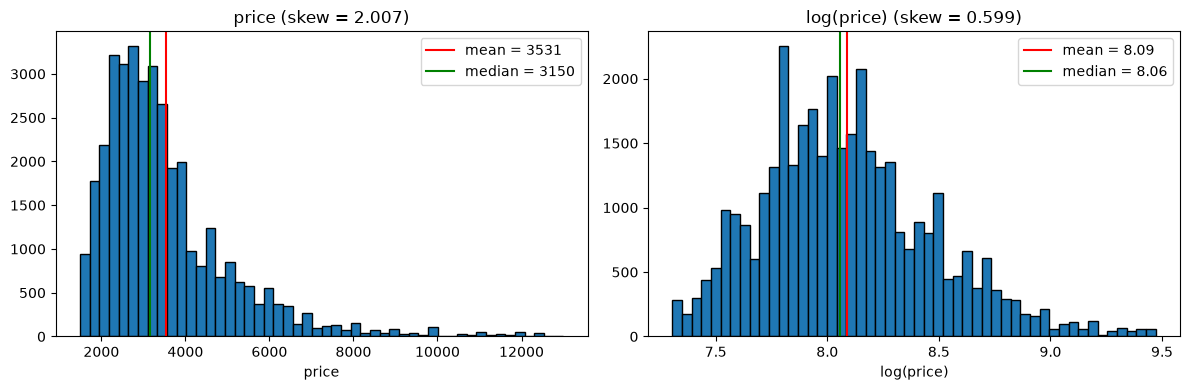

In [68]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].hist(y_train, bins=50, edgecolor='black')
axes[0].axvline(y_train.mean(), color='red', label=f'mean = {y_train.mean():.0f}')
axes[0].axvline(np.median(y_train), color='green', label=f'median = {np.median(y_train):.0f}')
axes[0].set_title(f'price (skew = {pd.Series(y_train).skew():.3f})')
axes[0].set_xlabel('price')
axes[0].legend()

log_y = np.log(y_train)
axes[1].hist(log_y, bins=50, edgecolor='black')
axes[1].axvline(log_y.mean(), color='red', label=f'mean = {log_y.mean():.2f}')
axes[1].axvline(np.median(log_y), color='green', label=f'median = {np.median(log_y):.2f}')
axes[1].set_title(f'log(price) (skew = {pd.Series(log_y).skew():.3f})')
axes[1].set_xlabel('log(price)')
axes[1].legend()

plt.tight_layout()
plt.show()

In [74]:

y_train_log = np.log(y_train)

class LogTargetWrapper:
    def __init__(self, base_model):
        self.base_model = base_model

    def fit(self, X, y):
        self.base_model.fit(X, np.log(np.asarray(y, dtype=np.float64)))
        return self

    def predict(self, X):
        return np.exp(self.base_model.predict(X))


sc = MyMinMaxScaler().fit(X_train)
Xtr_s, Xte_s = sc.transform(X_train), sc.transform(X_test)
for a in [1e-5, 1e-4, 1e-3, 1e-2]:
    m = LogTargetWrapper(Lasso(alpha=a)).fit(Xtr_s, y_train)
    print(f'alpha={a:<8} R2 test={my_r2_score(y_test, m.predict(Xte_s)):.4f}')
evaluate(m, 'Lasso MinMaxScaler + log(y)', Xtr_s, y_train, Xte_s, y_test)
show_results()


alpha=1e-05    R2 test=0.5626
alpha=0.0001   R2 test=0.5620
alpha=0.001    R2 test=0.5500
alpha=0.01     R2 test=0.3471

result_MAE


,model,train,test
0,My LinearRegression Analytic,707.529523,712.738504
1,My GD default,707.528571,712.729122
2,My SGD default,702.910304,707.847662
3,Linreg default (sklearn),707.529523,712.738504
4,Lasso default (sklearn),707.127193,711.851723
5,My Lasso default,707.125252,711.850433
6,Ridge default (sklearn),707.525176,712.730721
7,My Ridge default,707.525176,712.730721
8,ElasticNet default (sklearn),803.772798,798.252500
9,My ElasticNet default,803.772697,798.252389



result_RMSE


,model,train,test
0,My LinearRegression Analytic,1024.386593,1036.259660
1,My GD default,1024.387024,1036.257852
2,My SGD default,1025.561167,1036.789977
3,Linreg default (sklearn),1024.386593,1036.259660
4,Lasso default (sklearn),1024.587348,1035.888321
5,My Lasso default,1024.586228,1035.886692
6,Ridge default (sklearn),1024.386603,1036.255003
7,My Ridge default,1024.386603,1036.255003
8,ElasticNet default (sklearn),1180.324471,1173.695598
9,My ElasticNet default,1180.324427,1173.695568



result_R2


,model,train,test
0,My LinearRegression Analytic,0.585170,0.564824
1,My GD default,0.585170,0.564825
2,My SGD default,0.584218,0.564378
3,Linreg default (sklearn),0.585170,0.564824
4,Lasso default (sklearn),0.585008,0.565136
5,My Lasso default,0.585009,0.565137
6,Ridge default (sklearn),0.585170,0.564828
7,My Ridge default,0.585170,0.564828
8,ElasticNet default (sklearn),0.449262,0.441737
9,My ElasticNet default,0.449262,0.441737


In [78]:
class MyMiniBatchGD(MyLinearRegressionAnalytic):
    def __init__(self, lr=0.05, n_epochs=50, batch_size=64, random_state=21):
        self.lr = lr
        self.n_epochs = n_epochs
        self.batch_size = batch_size
        self.random_state = random_state
        self.w = None
        self.loss_history_ = []

    def fit(self, X, y):
        X = self._prepare(X)
        y = np.asarray(y, dtype=np.float64)
        n, d = X.shape
        rng = np.random.default_rng(self.random_state)

        self.w = np.zeros(d)
        self.w[0] = y.mean()

        for epoch in range(self.n_epochs):
            idx = rng.permutation(n)
            lr_epoch = self.lr / np.sqrt(1 + epoch)

            for start in range(0, n, self.batch_size):
                batch = idx[start:start + self.batch_size]
                Xb, yb = X[batch], y[batch]
                grad = -2 * Xb.T @ (yb - Xb @ self.w) / len(batch)
                self.w = self.w - lr_epoch * grad

            self.loss_history_.append(np.mean((y - X @ self.w) ** 2))
        return self

In [ ]:
mybatch = MyMiniBatchGD().fit(Xtr_s,y_train)

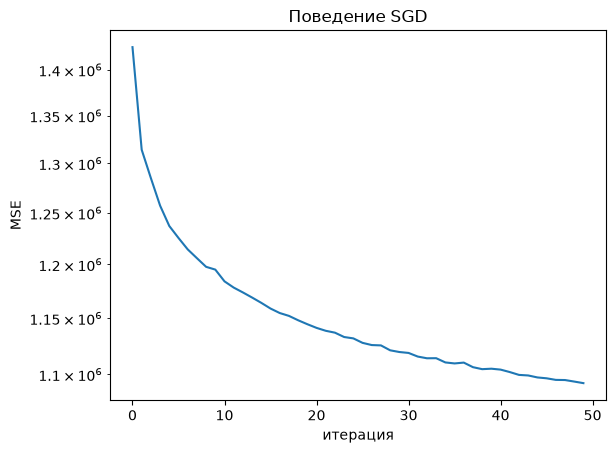

In [79]:
plt.plot(mybatch.loss_history_)
plt.xlabel('итерация') 
plt.ylabel('MSE')
plt.yscale('log')
plt.title('Поведение SGD')
plt.show()

In [76]:
evaluate(mybatch, 'MyMiniBatchGD', Xtr_s, y_train, Xte_s, y_test)
show_results()


result_MAE


,model,train,test
0,My LinearRegression Analytic,707.529523,712.738504
1,My GD default,707.528571,712.729122
2,My SGD default,702.910304,707.847662
3,Linreg default (sklearn),707.529523,712.738504
4,Lasso default (sklearn),707.127193,711.851723
5,My Lasso default,707.125252,711.850433
6,Ridge default (sklearn),707.525176,712.730721
7,My Ridge default,707.525176,712.730721
8,ElasticNet default (sklearn),803.772798,798.252500
9,My ElasticNet default,803.772697,798.252389



result_RMSE


,model,train,test
0,My LinearRegression Analytic,1024.386593,1036.259660
1,My GD default,1024.387024,1036.257852
2,My SGD default,1025.561167,1036.789977
3,Linreg default (sklearn),1024.386593,1036.259660
4,Lasso default (sklearn),1024.587348,1035.888321
5,My Lasso default,1024.586228,1035.886692
6,Ridge default (sklearn),1024.386603,1036.255003
7,My Ridge default,1024.386603,1036.255003
8,ElasticNet default (sklearn),1180.324471,1173.695598
9,My ElasticNet default,1180.324427,1173.695568



result_R2


,model,train,test
0,My LinearRegression Analytic,0.585170,0.564824
1,My GD default,0.585170,0.564825
2,My SGD default,0.584218,0.564378
3,Linreg default (sklearn),0.585170,0.564824
4,Lasso default (sklearn),0.585008,0.565136
5,My Lasso default,0.585009,0.565137
6,Ridge default (sklearn),0.585170,0.564828
7,My Ridge default,0.585170,0.564828
8,ElasticNet default (sklearn),0.449262,0.441737
9,My ElasticNet default,0.449262,0.441737
